In [10]:
import random
import itertools
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

In [20]:
students = ['aunye', 'ivan', 'barituaka', 'matthew', 'sonali', 'ethan', 'sam', 'owen', 'dulce', 'huy', 'luella', 'mamadou', 'luis', 'aurora', 'jordan']
len(students)

15

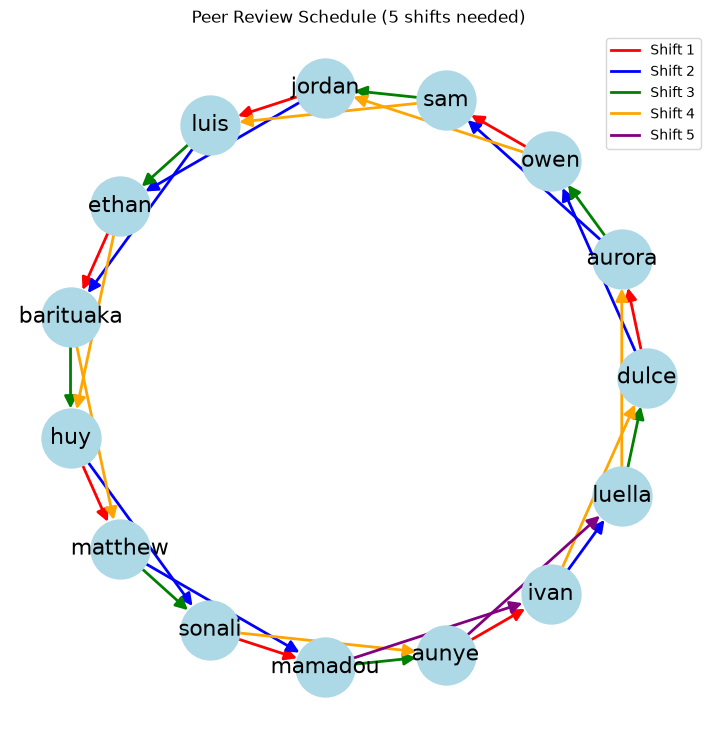


Shift 1:
  dulce -> talks to -> aurora
  owen -> talks to -> sam
  jordan -> talks to -> luis
  ethan -> talks to -> barituaka
  huy -> talks to -> matthew
  sonali -> talks to -> mamadou
  aunye -> talks to -> ivan

Shift 2:
  dulce -> talks to -> owen
  aurora -> talks to -> sam
  jordan -> talks to -> ethan
  luis -> talks to -> barituaka
  huy -> talks to -> sonali
  matthew -> talks to -> mamadou
  ivan -> talks to -> luella

Shift 3:
  aurora -> talks to -> owen
  luella -> talks to -> dulce
  sam -> talks to -> jordan
  luis -> talks to -> ethan
  barituaka -> talks to -> huy
  matthew -> talks to -> sonali
  mamadou -> talks to -> aunye

Shift 4:
  luella -> talks to -> aurora
  ivan -> talks to -> dulce
  owen -> talks to -> jordan
  sam -> talks to -> luis
  ethan -> talks to -> huy
  barituaka -> talks to -> matthew
  sonali -> talks to -> aunye

Shift 5:
  mamadou -> talks to -> ivan
  aunye -> talks to -> luella


(<networkx.classes.digraph.DiGraph at 0x76917af4ab70>,
 {('dulce', 'aurora'): 0,
  ('dulce', 'owen'): 1,
  ('aurora', 'owen'): 2,
  ('aurora', 'sam'): 1,
  ('luella', 'aurora'): 3,
  ('luella', 'dulce'): 2,
  ('ivan', 'dulce'): 3,
  ('owen', 'sam'): 0,
  ('owen', 'jordan'): 3,
  ('sam', 'jordan'): 2,
  ('sam', 'luis'): 3,
  ('jordan', 'luis'): 0,
  ('jordan', 'ethan'): 1,
  ('luis', 'ethan'): 2,
  ('luis', 'barituaka'): 1,
  ('ethan', 'barituaka'): 0,
  ('ethan', 'huy'): 3,
  ('barituaka', 'huy'): 2,
  ('barituaka', 'matthew'): 3,
  ('huy', 'matthew'): 0,
  ('huy', 'sonali'): 1,
  ('matthew', 'sonali'): 2,
  ('matthew', 'mamadou'): 1,
  ('sonali', 'mamadou'): 0,
  ('sonali', 'aunye'): 3,
  ('mamadou', 'aunye'): 2,
  ('mamadou', 'ivan'): 4,
  ('aunye', 'ivan'): 0,
  ('ivan', 'luella'): 1,
  ('aunye', 'luella'): 4})

In [21]:
def assign_peer_reviews_with_shifts(names, k=2, seed=None):
    n = len(names)
    assert k < n

    # --- 1. Build balanced review graph (circulant assignment) ---
    order = names[:]
    random.seed(seed)
    random.shuffle(order)

    G = nx.DiGraph()
    G.add_nodes_from(order)
    for i, reviewer in enumerate(order):
        for j in range(1, k + 1):
            reviewee = order[(i + j) % n]
            G.add_edge(reviewer, reviewee)

    # --- 2. Build conflict graph over EDGES ---
    H = nx.Graph()
    H.add_nodes_from(G.edges())
    for (a, b), (c, d) in itertools.combinations(G.edges(), 2):
        if {a, b} & {c, d}:          # any shared vertex => conflict
            H.add_edge((a, b), (c, d))

    # --- 3. Color the conflict graph -> each color = one shift ---
    color_map = nx.coloring.greedy_color(H, strategy="saturation_largest_first")
    num_shifts = max(color_map.values()) + 1

    # --- 4. Distinct colors ---
    palette = ["red", "blue", "green", "orange", "purple", "brown"]
    if num_shifts > len(palette):
        raise ValueError(f"Need {num_shifts} colors but only {len(palette)} provided.")

    # --- 5. Visualize ---
    pos = nx.circular_layout(G)
    plt.figure(figsize=(9, 9))
    nx.draw_networkx_nodes(G, pos, node_color="lightblue", node_size=1800)
    nx.draw_networkx_labels(G, pos, font_size=16)

    ax = plt.gca()
    for shift in range(num_shifts):
        edges_in_shift = [e for e, c in color_map.items() if c == shift]
        nx.draw_networkx_edges(
            G, pos, edgelist=edges_in_shift,
            edge_color=palette[shift],
            arrows=True, arrowstyle="-|>", arrowsize=18, width=2,
            connectionstyle="arc3,rad=0.0",
            node_size=1800,   # <-- add this so arrow doesn't get swallowed by node
            ax=ax
        )

    legend_elems = [
        Line2D([0], [0], color=palette[s], lw=2, label=f"Shift {s+1}")
        for s in range(num_shifts)
    ]
    plt.legend(handles=legend_elems, loc="upper right")
    plt.title(f"Peer Review Schedule ({num_shifts} shifts needed)")
    plt.axis("equal")
    plt.axis("off")
    plt.show()

    # --- 6. Print schedule as text ---
    for shift in range(num_shifts):
        print(f"\nShift {shift+1}:")
        for (a, b), c in color_map.items():
            if c == shift:
                print(f"  {a} -> talks to -> {b}")

    return G, color_map


# Example usage:
# students = [f"Student {i+1}" for i in range(15)]
assign_peer_reviews_with_shifts(students, k=2, seed=42)

In [21]:
df = pandas.read_csv("GTEx_Analysis_2025-08-22_v11_RNASeQCv2.4.3_gene_median_tpm.gct.gz", 
sep="\t", 
header=2, 
index_col='Description')

In [3]:
df.shape

(74628, 69)

In [4]:
df.head()

,Name,Adipose_Subcutaneous,Adipose_Visceral_Omentum,Adrenal_Gland,Artery_Aorta,Artery_Coronary,Artery_Tibial,Bladder,Brain_Amygdala,Brain_Anterior_cingulate_cortex_BA24,...,Spleen,Stomach,Stomach_Mixed_Cell,Stomach_Mucosa,Stomach_Muscularis,Testis,Thyroid,Uterus,Vagina,Whole_Blood
Description,,,,,,,,,,,,,,,,,,,,,
DDX11L16,ENSG00000290825.2,0.00000,0.0000,0.00000,0.0000,0.00000,0.00000,0.00000,0.011780,0.000000,...,0.00000,0.00000,0.014928,0.012652,0.015991,0.073208,0.00000,0.00000,0.00000,0.0000
DDX11L1,ENSG00000223972.6,0.00000,0.0000,0.00000,0.0000,0.00000,0.00000,0.00000,0.000000,0.000000,...,0.00000,0.00000,0.000000,0.000000,0.000000,0.000000,0.00000,0.00000,0.00000,0.0000
WASH7P,ENSG00000310526.1,2.45431,1.9053,1.75253,2.3178,2.21944,1.66539,3.14825,0.565228,0.652863,...,5.04503,2.04517,1.868420,1.507490,1.909350,3.126710,4.01324,4.92657,3.85789,2.2098
MIR1302-2HG,ENSG00000243485.6,0.00000,0.0000,0.00000,0.0000,0.00000,0.00000,0.00000,0.000000,0.000000,...,0.00000,0.00000,0.000000,0.000000,0.000000,0.036257,0.00000,0.00000,0.00000,0.0000
FAM138A,ENSG00000237613.3,0.00000,0.0000,0.00000,0.0000,0.00000,0.00000,0.00000,0.012860,0.013432,...,0.00000,0.00000,0.015325,0.013091,0.018168,0.000000,0.00000,0.00000,0.00000,0.0000


In [22]:
df = df.drop("Name", axis=1)

In [23]:
df.shape

(74628, 68)

In [25]:
df = numpy.log10(df)

/home/davidb/miniforge3/envs/srpp_env/lib/python3.14/site-packages/pandas/core/internals/blocks.py:347: RuntimeWarning: divide by zero encountered in log10
  result = func(self.values, **kwargs)


<Axes: ylabel='Count'>

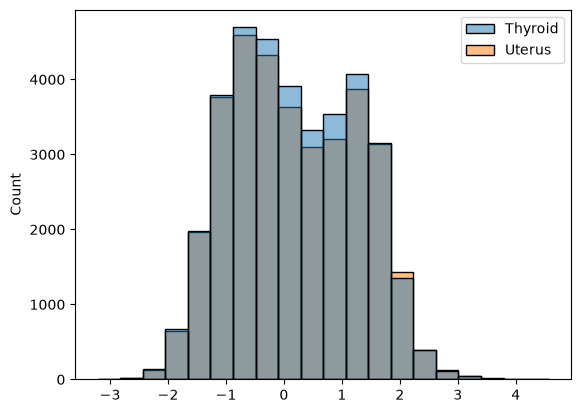

In [32]:
seaborn.histplot([df['Thyroid'], df['Uterus']], bins=20)

<Axes: xlabel='NOVA2', ylabel='TUBB'>

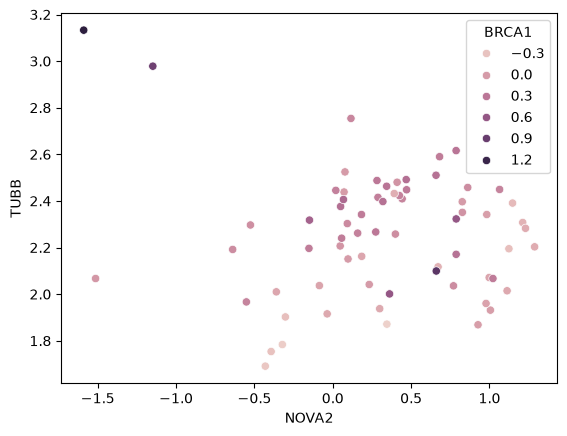

In [38]:
seaborn.scatterplot(x=df.loc['NOVA2'], y=df.loc['TUBB'], hue=df.loc['BRCA1'])

In [45]:
10 ** df.loc['BRCA1']['Breast_Mammary_Tissue']

np.float64(1.18184)

In [43]:
df.columns

Index(['Adipose_Subcutaneous', 'Adipose_Visceral_Omentum', 'Adrenal_Gland',
       'Artery_Aorta', 'Artery_Coronary', 'Artery_Tibial', 'Bladder',
       'Brain_Amygdala', 'Brain_Anterior_cingulate_cortex_BA24',
       'Brain_Caudate_basal_ganglia', 'Brain_Cerebellar_Hemisphere',
       'Brain_Cerebellum', 'Brain_Cortex', 'Brain_Frontal_Cortex_BA9',
       'Brain_Hippocampus', 'Brain_Hypothalamus',
       'Brain_Nucleus_accumbens_basal_ganglia', 'Brain_Putamen_basal_ganglia',
       'Brain_Spinal_cord_cervical_c-1', 'Brain_Substantia_nigra',
       'Breast_Mammary_Tissue', 'Cells_Cultured_fibroblasts',
       'Cells_EBV-transformed_lymphocytes', 'Cervix_Ectocervix',
       'Cervix_Endocervix', 'Colon_Sigmoid', 'Colon_Transverse',
       'Colon_Transverse_Mixed_Cell', 'Colon_Transverse_Mucosa',
       'Colon_Transverse_Muscularis', 'Esophagus_Gastroesophageal_Junction',
       'Esophagus_Mucosa', 'Esophagus_Muscularis', 'Fallopian_Tube',
       'Heart_Atrial_Appendage', 'Heart_Left_Ventr

In [50]:
ann = pandas.read_csv("gencode.v47.annotation.chr22.gtf", sep='\t', header=None)

In [59]:
ann.head()

,chromosome,source,feature,start,end,idk,strand,idk2,description
0,chr22,HAVANA,gene,10524345,10529164,.,-,.,"gene_id ""ENSG00000294541.1""; gene_type ""lncRNA..."
1,chr22,HAVANA,transcript,10524345,10529164,.,-,.,"gene_id ""ENSG00000294541.1""; transcript_id ""EN..."
2,chr22,HAVANA,exon,10529036,10529164,.,-,.,"gene_id ""ENSG00000294541.1""; transcript_id ""EN..."
3,chr22,HAVANA,exon,10527853,10528040,.,-,.,"gene_id ""ENSG00000294541.1""; transcript_id ""EN..."
4,chr22,HAVANA,exon,10524345,10524446,.,-,.,"gene_id ""ENSG00000294541.1""; transcript_id ""EN..."


In [58]:
ann = ann.rename(columns={0: "chromosome", 
1: "source", 
2: "feature", 
3: "start", 
4: "end", 
5: "idk", 
6: "strand", 
7: "idk2", 
8: "description", })